<a href="https://colab.research.google.com/github/rohit-jain8/Problem-Set-5/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS5 | Right 93% of the Time
Rohit Jain

## Phase 1 | Data and baseline

I simulated 10,000 loan applications. Five variables affect default in the simulation, and the last three are just noise. I used 60% of the data to train the models, 10% to fit the calibration models, 10% to pick a cutoff and check calibration, and 20% for the final test.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

seed = 42
rng = np.random.default_rng(seed)
n = 10_000
X = pd.DataFrame({
    "income": rng.lognormal(np.log(65_000), 0.45, n),
    "debt_to_income": 0.8 * rng.beta(2.5, 5, n),
    "credit_history_years": np.clip(rng.gamma(3, 4, n), 0.5, 40),
    "prior_delinquencies": rng.poisson(0.45, n),
    "loan_amount": rng.lognormal(np.log(14_000), 0.50, n).clip(1_000, 60_000),
    "application_minute": rng.integers(0, 60, n),
    "form_version": rng.integers(1, 4, n),
    "noise_score": rng.normal(size=n),
})
noise = X.columns[-3:].tolist()
log_odds = (
    -3.60 - 0.60 * np.log(X.income / 65_000)
    + 5.0 * (X.debt_to_income - 0.27)
    - 0.055 * (X.credit_history_years - 12)
    + 0.95 * X.prior_delinquencies
    + 0.55 * np.log(X.loan_amount / 14_000)
    + 0.90 * ((X.debt_to_income > 0.40) & (X.prior_delinquencies >= 1))
)
default_prob = 1 / (1 + np.exp(-log_odds))
y = rng.binomial(1, default_prob)
train, held = train_test_split(np.arange(n), test_size=0.4, stratify=y, random_state=seed)
test, tuning = train_test_split(held, test_size=0.5, stratify=y[held], random_state=seed)
cal, val = train_test_split(tuning, test_size=0.5, stratify=y[tuning], random_state=seed)
X_train, y_train = X.iloc[train], y[train]
X_test, y_test = X.iloc[test], y[test]
X_cal, y_cal = X.iloc[cal], y[cal]
X_val, y_val = X.iloc[val], y[val]
null_pred = np.zeros_like(y_test)
baseline = accuracy_score(y_test, null_pred)
print(f"Test default prevalence: {y_test.mean():.2%}")
print(f"Approve-all test accuracy: {baseline:.2%}")

Test default prevalence: 7.65%
Approve-all test accuracy: 92.35%


Approving every application was 92.35% accurate and caught zero defaults. That tells me why the vendor's 93% accuracy is hard to judge on its own.

## Phase 2 | Fit and regularize

I used five-fold cross-validation on the training set to choose the penalties for LASSO and Ridge. I used average precision to pick the penalties because defaults are rare. The scaler is inside the pipeline so it only learns from the training rows in each fold. I use Ridge for the threshold analysis and compare its accuracy with the forest at 0.50.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
models = {"Logistic": make_pipeline(StandardScaler(), LogisticRegression(penalty=None, max_iter=3000))}
for name, penalty in [("LASSO", "l1"), ("Ridge", "l2")]:
    pipeline = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty=penalty, solver="saga", max_iter=5000, random_state=seed),
    )
    models[name] = GridSearchCV(
        pipeline, {"logisticregression__C": np.logspace(-3, 2, 16)},
        cv=cv, scoring="average_precision",
    )

for model in models.values():
    model.fit(X_train, y_train)

print("Selected inverse penalty strengths (C)")
for name in ("LASSO", "Ridge"):
    print(name, models[name].best_params_["logisticregression__C"])

coef = pd.Series(
    models["LASSO"].best_estimator_.named_steps["logisticregression"].coef_[0],
    index=X.columns,
)
zeroed = coef.index[coef.eq(0)].tolist()
print("Exactly zero:", zeroed)
print("LASSO standardized coefficients")
print(coef.round(4).to_string())

Selected inverse penalty strengths (C)
LASSO 0.21544346900318823
Ridge 1.0
Exactly zero: []
LASSO standardized coefficients
income                 -0.3330
debt_to_income          0.7802
credit_history_years   -0.3170
prior_delinquencies     0.6616
loan_amount             0.2212
application_minute     -0.0477
form_version            0.0042
noise_score            -0.0449


LASSO did not set any coefficients to zero. It dropped 0 of the 3 noise variables and 0 of the 5 real predictors. LASSO penalizes the absolute size of each coefficient, which lets it set small ones to zero. Ridge uses squared coefficients, so it shrinks them toward zero. I'd use LASSO if I wanted a shorter list of predictors and Ridge if I wanted to keep predictors that share some of the same information.

In [3]:
rf = RandomForestClassifier(
    n_estimators=500, oob_score=True, bootstrap=True, random_state=seed, n_jobs=2,
).fit(X_train, y_train)
models["Forest"] = rf
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob),
        "Average precision": average_precision_score(y_test, prob),
    })
scores = pd.DataFrame(rows).set_index("Model")
pred_rf = rf.predict(X_test)
pred_ridge = models["Ridge"].predict(X_test)
print(f"OOB accuracy: {rf.oob_score_:.2%} | OOB error: {1 - rf.oob_score_:.2%}")
print(scores.round(4).to_string())
permuted = permutation_importance(
    rf, X_test, y_test, scoring="average_precision", n_repeats=12, random_state=seed,
)
importance = pd.DataFrame({
    "MDI": rf.feature_importances_,
    "Test AP drop": permuted.importances_mean,
    "Shuffle SD": permuted.importances_std,
}, index=X.columns).sort_values("MDI", ascending=False)
print()
print(importance.round(4).to_string())

OOB accuracy: 92.52% | OOB error: 7.48%
          Accuracy  ROC AUC  Average precision
Model                                         
Logistic    0.9275   0.7809             0.3215
LASSO       0.9260   0.7812             0.3205
Ridge       0.9275   0.7809             0.3215
Forest      0.9260   0.7686             0.3159

                         MDI  Test AP drop  Shuffle SD
debt_to_income        0.2077        0.1805      0.0133
income                0.1490        0.0496      0.0111
credit_history_years  0.1448        0.0276      0.0115
loan_amount           0.1431        0.0311      0.0071
noise_score           0.1353        0.0061      0.0064
application_minute    0.1055        0.0131      0.0058
prior_delinquencies   0.0830        0.1544      0.0157
form_version          0.0317        0.0108      0.0040


The forest's OOB accuracy was 92.52%, so its OOB error rate was 7.48%. Its test accuracy was 92.60%. I expected these to be close because both use rows the trees did not train on. A big gap would make me check whether the training and test samples are similar.

Ridge was slightly ahead of the forest on test accuracy (92.75% vs. 92.60%) and average precision (0.322 vs. 0.316).

The noise score received an MDI of 0.135, but shuffling it only lowered average precision by 0.006. Prior delinquencies had a lower MDI of 0.083, but shuffling them lowered average precision by 0.154. A continuous variable gives the forest more places to split, so some splits can look good just by chance. Prior delinquencies can help flag a loan for review, but declining the loan won't undo a delinquency.

## Phase 3 | Metrics and decision cost

The confusion matrix has actual outcomes in the rows and predictions in the columns. Class 1 means the applicant defaulted or the model predicted default, depending on the axis. A predicted 1 means the lender declines the application.

[[1842    5]
 [ 140   13]]
Accuracy                0.9275
Precision               0.7222
Recall                  0.0850
F1                      0.1520
ROC AUC                 0.7809
PR AUC (trapezoidal)    0.3179
Average precision       0.3215


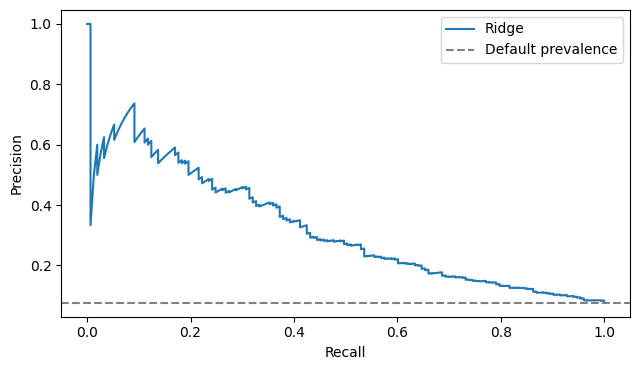

In [4]:
ridge = models["Ridge"]
y_prob = ridge.predict_proba(X_test)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_prob)
metrics = {
    "Accuracy": accuracy_score(y_test, pred_ridge),
    "Precision": precision_score(y_test, pred_ridge, zero_division=0),
    "Recall": recall_score(y_test, pred_ridge),
    "F1": f1_score(y_test, pred_ridge),
    "ROC AUC": roc_auc_score(y_test, y_prob),
    "PR AUC (trapezoidal)": auc(recall, precision),
    "Average precision": average_precision_score(y_test, y_prob),
}
print(confusion_matrix(y_test, pred_ridge, labels=[0, 1]))
print(pd.Series(metrics).round(4).to_string())
plt.figure(figsize=(6.5, 3.8))
plt.plot(recall, precision, label="Ridge")
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="Default prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

At 0.50, Ridge had 72.2% precision and 8.5% recall. Its ROC AUC was 0.781 and its PR AUC was 0.318. With so many good loans, even a small false-positive rate can mean turning away a lot of borrowers. The precision-recall curve shows what share of flagged loans default as I try to catch more defaults.

### What each mistake costs

I assumed an approved loan that defaults costs 60% of its principal. For declining a good loan, I used 8% in missed interest margin and another 2% for lost goodwill and possible future business. I used 2% as an assumption because I don't have data on that cost. Correct decisions have zero cost in this calculation.

I tried cutoffs from 0 to 1 in increments of 0.001. I used validation to pick the cutoff and also show where the cost was lowest on the test set. If the model's probabilities are calibrated, the cost-based cutoff is 0.10 / (0.60 + 0.10), or 14.29%.

                    threshold      TN     FP     FN    TP      cost
Approve all               inf  1847.0    0.0  153.0   0.0  830.1380
Default cutoff          0.500  1842.0    5.0  140.0  13.0  753.6271
Validation minimum      0.190  1698.0  149.0   87.0  66.0  577.6993
Test minimum            0.202  1716.0  131.0   88.0  65.0  562.3699


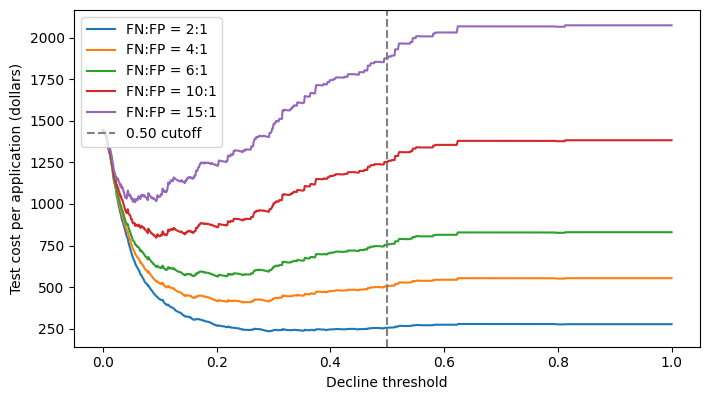

 FN:FP  Test minimum  Calibrated cutoff
     2         0.292             0.3333
     4         0.245             0.2000
     6         0.202             0.1429
    10         0.094             0.0909
    15         0.057             0.0625


In [5]:
fn_rate = 0.60
fp_rate = 0.10
test_amount = X_test.loan_amount.to_numpy()
val_amount = X_val.loan_amount.to_numpy()
p_val = ridge.predict_proba(X_val)[:, 1]

def cost_curve(prob, actual, principal, false_negative=fn_rate, false_positive=fp_rate):
    thresholds = np.linspace(0, 1, 1001)
    costs = []
    for threshold in thresholds:
        decline = prob >= threshold
        missed_defaults = (actual == 1) & (decline == 0)
        declined_good_loans = (actual == 0) & (decline == 1)
        default_cost = false_negative * principal[missed_defaults].sum()
        decline_cost = false_positive * principal[declined_good_loans].sum()
        costs.append((default_cost + decline_cost) / len(actual))
    return pd.Series(costs, index=thresholds, name="Cost per application (dollars)")


def decision_summary(prob, threshold, actual=y_test, principal=test_amount):
    decline = prob >= threshold
    tn, fp, fn, tp = confusion_matrix(actual, decline, labels=[0, 1]).ravel()
    default_cost = fn_rate * principal[(actual == 1) & (decline == 0)].sum()
    decline_cost = fp_rate * principal[(actual == 0) & (decline == 1)].sum()
    return dict(threshold=threshold, TN=tn, FP=fp, FN=fn, TP=tp,
                cost=(default_cost + decline_cost) / len(actual))

raw_validation = cost_curve(p_val, y_val, val_amount)
raw_test = cost_curve(y_prob, y_test, test_amount)
raw_threshold = raw_validation.idxmin()
test_min = raw_test.idxmin()
policies = {
    "Approve all": decision_summary(y_prob, np.inf),
    "Default cutoff": decision_summary(y_prob, 0.5),
    "Validation minimum": decision_summary(y_prob, raw_threshold),
    "Test minimum": decision_summary(y_prob, test_min),
}
print(pd.DataFrame(policies).T.round(4).to_string())

ratios = [2, 4, 6, 10, 15]
sensitivity = []
plt.figure(figsize=(7.2, 4.1))
for ratio in ratios:
    curve = cost_curve(y_prob, y_test, test_amount, ratio * fp_rate, fp_rate)
    sensitivity.append((ratio, curve.idxmin(), 1 / (1 + ratio)))
    plt.plot(curve.index, curve, label=f"FN:FP = {ratio}:1")
plt.axvline(0.5, linestyle="--", color="gray", label="0.50 cutoff")
plt.xlabel("Decline threshold")
plt.ylabel("Test cost per application (dollars)")
plt.legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame(sensitivity, columns=["FN:FP", "Test minimum", "Calibrated cutoff"])
      .round(4).to_string(index=False))

The lowest test-set cost was at 0.202, which is 0.298 below 0.50. The confusion matrix went from [[1842, 5], [140, 13]] at 0.50 to [[1716, 131], [88, 65]] at the test minimum. I caught more defaults, but also turned away more good borrowers.

The cutoff I picked using validation was 0.190. It cost 577.70 dollars per test application, compared with 830.14 dollars for approving everyone.

I'd lower the cutoff if missing a default gets more expensive and raise it if turning away a good borrower gets more expensive. On the test set, the lowest-cost cutoff fell from 0.292 to 0.057 as the cost ratio went from 2:1 to 15:1.

## Phase 4 | Check the results

### Part A | Ridge vs. the random forest

Both models made predictions on the same test applications. I counted the cases where the forest was right and Ridge was wrong (b), and the cases where Ridge was right and the forest was wrong (c). Those are the rows that tell me which model made fewer mistakes.

In [6]:
forest_right = pred_rf == y_test
ridge_right = pred_ridge == y_test
b = int(np.sum(forest_right & ~ridge_right))
c = int(np.sum(~forest_right & ridge_right))
paired = np.array([
    [np.sum(forest_right & ridge_right), b],
    [c, np.sum(~forest_right & ~ridge_right)],
])
discordant = b + c
if discordant == 0:
    p_value, variant = 1.0, "No discordant rows"
elif discordant < 25:
    p_value = binomtest(b, discordant, 0.5).pvalue
    variant = "Exact binomial because fewer than 25 rows are discordant"
else:
    statistic = max(abs(b - c) - 1, 0)**2 / discordant
    p_value = chi2.sf(statistic, df=1)
    variant = "Continuity-corrected chi-square because at least 25 rows are discordant"
print(paired)
print(f"b={b}, c={c}, b+c={discordant}, p={p_value:.4f}")
print(variant)

[[1842   10]
 [  13  135]]
b=10, c=13, b+c=23, p=0.6776
Exact binomial because fewer than 25 rows are discordant


The forest got 10 cases right that Ridge missed, and Ridge got 13 right that the forest missed. I used the exact two-sided McNemar test because only 23 rows were discordant. The p-value was 0.678, so Ridge was slightly ahead on accuracy, but there isn't enough evidence to say the two models differ. The AI reply also used McNemar and assumed the two predictions for each row were paired. I'd compare dollar loss at cutoffs chosen ahead of time to see whether one model actually costs the lender less.

### Part B | Calibration

I fitted Platt scaling and isotonic regression on the calibration split, then checked their Brier scores on the validation and test sets. I grouped the test predictions into ten groups of 200 so the high-risk points wouldn't be based on just a few applications.

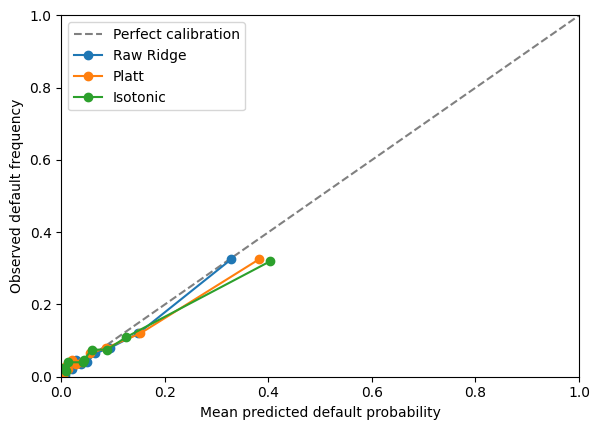

200 test applications per rank group.
    Model  Validation Brier  Test Brier  Reliability  Resolution  Uncertainty  Binned Brier  Within-bin adjustment
Raw Ridge           0.05998     0.06116      0.00017     0.00783      0.07065       0.06298               -0.00182
    Platt           0.06064     0.06143      0.00056     0.00783      0.07065       0.06338               -0.00195
 Isotonic           0.06221     0.06190      0.00093     0.00737      0.07065       0.06421               -0.00231

                                     threshold      TN     FP    FN    TP      cost
Raw empirical threshold                 0.1900  1698.0  149.0  87.0  66.0  577.6993
Selected score, validation minimum      0.1900  1698.0  149.0  87.0  66.0  577.6993
Selected score, cost-implied policy     0.1429  1623.0  224.0  72.0  81.0  573.7953


In [7]:
def log_odds_column(prob):
    prob = np.clip(prob, 1e-8, 1 - 1e-8)
    return np.log(prob / (1 - prob)).reshape(-1, 1)

p_cal = ridge.predict_proba(X_cal)[:, 1]
platt = LogisticRegression(penalty=None).fit(log_odds_column(p_cal), y_cal)
isotonic = IsotonicRegression(out_of_bounds="clip").fit(p_cal, y_cal)

def probability_versions(prob):
    return {
        "Raw Ridge": prob,
        "Platt": platt.predict_proba(log_odds_column(prob))[:, 1],
        "Isotonic": isotonic.predict(prob),
    }

cal_val, cal_test = probability_versions(p_val), probability_versions(y_prob)
validation_brier = pd.Series({
    "Raw Ridge": brier_score_loss(y_val, cal_val["Raw Ridge"]),
    "Platt": brier_score_loss(y_val, cal_val["Platt"]),
    "Isotonic": brier_score_loss(y_val, cal_val["Isotonic"]),
})
selected = validation_brier.idxmin()

def reliability_groups(prob, actual, n_groups=10):
    sorted_rows = np.argsort(prob)
    groups = np.array_split(sorted_rows, n_groups)
    rows = []
    for group in groups:
        rows.append({
            "count": len(group),
            "mean_probability": prob[group].mean(),
            "observed_rate": actual[group].mean(),
        })
    return pd.DataFrame(rows)

uncertainty = y_test.mean() * (1 - y_test.mean())
plt.figure(figsize=(6.1, 4.4))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
decomposition = []
for name, prob in cal_test.items():
    bins = reliability_groups(prob, y_test)
    weights = bins["count"] / len(y_test)
    reliability = (weights * (bins.mean_probability - bins.observed_rate)**2).sum()
    resolution = (weights * (bins.observed_rate - y_test.mean())**2).sum()
    brier = brier_score_loss(y_test, prob)
    binned_brier = uncertainty - resolution + reliability
    decomposition.append({
        "Model": name, "Validation Brier": validation_brier[name], "Test Brier": brier,
        "Reliability": reliability, "Resolution": resolution, "Uncertainty": uncertainty,
        "Binned Brier": binned_brier, "Within-bin adjustment": brier - binned_brier,
    })
    plt.plot(bins.mean_probability, bins.observed_rate, marker="o", label=name)
max_rate = max(max(p.max() for p in cal_test.values()), .4)
plt.xlim(0, min(1, max_rate + .03))
plt.ylim(0, min(1, max_rate + .03))
plt.xlabel("Mean predicted default probability")
plt.ylabel("Observed default frequency")
plt.legend()
plt.tight_layout()
plt.show()
print("200 test applications per rank group.")
print(pd.DataFrame(decomposition).round(5).to_string(index=False))
recommended_cutoff = fp_rate / (fp_rate + fn_rate)
recommended = decision_summary(cal_test[selected], recommended_cutoff)
calibrated_min = cost_curve(
    cal_val[selected], y_val, val_amount,
).idxmin()
print()
print(pd.DataFrame({
    "Raw empirical threshold": policies["Validation minimum"],
    "Selected score, validation minimum": decision_summary(cal_test[selected], calibrated_min),
    "Selected score, cost-implied policy": recommended,
}).T.round(4).to_string())

Raw Ridge had the lowest Brier score on validation and on test. On the test set, the scores were 0.06116 for Ridge, 0.06143 for Platt, and 0.06190 for isotonic. I kept the raw probabilities and the 0.190 cutoff from the validation sweep as a candidate. The Brier decomposition uses the average prediction in each group. The adjustment shows the difference between that grouped score and the score from the individual predictions.

A model can rank borrowers correctly even if its probabilities are off. That matters because a lender using a fixed cutoff needs the probability to be accurate around that cutoff. I would test 14.29% as a separate cutoff based on the costs above. I'd check how well the probabilities match actual default rates near that cutoff on real applications before using it.

### Recommendation to the head of risk

I would hold off on signing. Approving everyone was already 92.35% accurate in the simulation, and Ridge at 0.50 caught only 8.5% of defaults. I'd test a 14.29% decline cutoff using Ridge's predicted probabilities. That cutoff cost 573.80 dollars per application on the test set, compared with 830.14 dollars for approving everyone. I assumed the lender loses 60% of principal when an approved loan defaults and 10% when a good loan is declined. That 10% includes 8% in missed interest margin and 2% for lost goodwill.

I'd reconsider if the lender tested this cutoff on its own applications and found that it lowered actual costs compared with approving everyone.

## AI Transcript

~~~~text
Model for both exchanges: ChatGPT (Codex). Date: November 23, 2026.

### Part A | Prompt

[Prep] Act as a model risk analyst comparing two candidate credit models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The random forest got 0.9?? accuracy and the penalised logistic model got 0.9??. Write Python that tells me whether the forest is significantly better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

### Part A | Reply

Use a **one-sided exact McNemar test** for the prespecified question of whether the forest has higher accuracy. Replace `rf_pred` and `logit_pred` with your existing prediction-array names.

```python
import numpy as np  # Compare predicted class labels with the true labels.
from scipy.stats import binomtest  # Compute the exact one-sided p-value.

y, forest, logit = map(np.asarray, (y_test, rf_pred, logit_pred))  # Read the three existing arrays.
if y.ndim != 1 or y.size == 0 or forest.shape != y.shape or logit.shape != y.shape:  # Check the input dimensions.
    raise ValueError("Use nonempty 1D arrays with one label per test case.")  # Stop if the dimensions differ.

forest_correct = forest == y  # Identify the cases the forest classified correctly.
logit_correct = logit == y  # Identify the cases the logistic model classified correctly.
forest_only = np.count_nonzero(forest_correct & ~logit_correct)  # Count cases only the forest got right.
logit_only = np.count_nonzero(logit_correct & ~forest_correct)  # Count cases only the logistic model got right.
discordant = forest_only + logit_only  # Count cases where exactly one model was correct.
p_value = binomtest(forest_only, discordant, 0.5, alternative="greater").pvalue if discordant else 1.0  # Use p=1 if every case ties.
gap_pp = 100 * (forest_only - logit_only) / y.size  # Calculate the accuracy gap in percentage points.
print(f"Forest minus logistic accuracy: {gap_pp:+.2f} pp; one-sided p-value: {p_value:.6g}")  # Report both results.
```

The predictions must be class labels for the same held-out cases in the same order. The test assumes independence across case pairs and allows the two predictions for each case to be dependent. Under equal accuracy, either model is equally likely to be the sole correct model on a discordant case. The reported aggregate accuracies alone cannot determine the p-value.

**For the head of risk:** “On the held-out test set, the forest’s accuracy was [signed gap] percentage points relative to penalised logistic regression, with a one-sided exact McNemar p-value of [p] for higher forest accuracy.”
~~~~

I used the same paired counts as the AI reply and added the 2 by 2 table. I used the two-sided test for the notebook comparison.

### Part B | Prompt

~~~~text
[Prep] Act as a model risk analyst at a bank, reviewing a credit scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities on a test set with about 7% prevalence. Write Python that assesses CALIBRATION -- a reliability diagram binning predicted probability against observed frequency, plus the Brier score and its decomposition -- and then applies both Platt scaling and isotonic regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and y_prob. Handle the sparse high-probability bins that low prevalence creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly -- high AUC -- and still be badly calibrated, and why that distinction decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold valid? If not, what should I do before using it?

### Part B | Reply

Evaluate both recalibrators on the same untouched observations. Pool sparse bins using predicted probabilities and sample counts, then report observed defaults, bin sizes, and Wilson intervals. Report the raw Brier score alongside the exact decomposition for bin-mean forecasts and the difference between the two scores.

AUC measures ranking. A strictly increasing transformation preserves rankings and AUC while changing the probabilities and which applicants cross a fixed cutoff. The Phase 3 threshold cannot be validated without the diagram, cutoff, and cost assumptions. Check reliability and realized decision costs near the cutoff on independent data before using it.

### Part B | Follow-up prompt

Please provide the runnable Python requested in the original prompt. Assume y_test and y_prob are the only arrays available. Keep the code self-contained using scikit-learn, NumPy, and Matplotlib.

### Part B | Follow-up reply

Run this after defining `y_test` and `y_prob`. Set `threshold` to your Phase 3 cutoff if you want the diagram and tables to flag the bin containing it. The split reserves half of the available predictions for evaluation.

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split


def pooled_bins(p, min_count, max_bins):
    """Return contiguous probability bins without splitting tied predictions."""
    quantiles = np.linspace(0, 1, max_bins + 1)[1:-1]
    cuts = np.unique(np.quantile(p, quantiles))
    labels = np.searchsorted(cuts, p, side="left")
    bins, pending = [], []
    count = 0

    for label in np.unique(labels):
        rows = np.flatnonzero(labels == label)
        pending.append(rows)
        count += rows.size
        if count >= min_count:
            bins.append(np.concatenate(pending))
            pending, count = [], 0

    if pending:
        tail = np.concatenate(pending)
        if bins:
            bins[-1] = np.concatenate((bins[-1], tail))
        else:
            bins.append(tail)
    return bins


def wilson_interval(events, n):
    z = 1.959963984540054
    rate = events / n
    denominator = 1 + z**2 / n
    center = (rate + z**2 / (2 * n)) / denominator
    radius = z * np.sqrt(rate * (1 - rate) / n + z**2 / (4 * n**2))
    radius /= denominator
    return max(0.0, center - radius), min(1.0, center + radius)


def assess_calibration(y_test, y_prob, threshold=None, min_count=300,
                       max_bins=10, random_state=42):
    y = np.asarray(y_test).ravel()
    p = np.asarray(y_prob, dtype=float).ravel()
    if y.size != p.size or not np.array_equal(np.unique(y), [0, 1]):
        raise ValueError("Provide matching arrays with both binary labels 0 and 1.")
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("y_prob must contain finite probabilities in [0, 1].")
    if np.bincount(y.astype(int)).min() < 2:
        raise ValueError("Each class needs at least two observations for the split.")
    if min_count < 1 or max_bins < 1:
        raise ValueError("min_count and max_bins must be positive.")
    if threshold is not None and not 0 <= threshold <= 1:
        raise ValueError("threshold must be in [0, 1].")

    fit_rows, eval_rows = train_test_split(
        np.arange(y.size), test_size=0.5, stratify=y, random_state=random_state
    )
    y_fit, y_eval = y[fit_rows], y[eval_rows]
    p_fit, p_eval = p[fit_rows], p[eval_rows]

    def logit(probability):
        clipped = np.clip(probability, 1e-12, 1 - 1e-12)
        return (np.log(clipped) - np.log1p(-clipped)).reshape(-1, 1)

    platt = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000)
    platt.fit(logit(p_fit), y_fit)
    isotonic = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip")
    isotonic.fit(p_fit, y_fit)

    forecasts = {
        "Raw": p_eval,
        "Platt": platt.predict_proba(logit(p_eval))[:, 1],
        "Isotonic": isotonic.predict(p_eval),
    }
    base_rate = y_eval.mean()
    uncertainty = base_rate * (1 - base_rate)
    raw_brier = brier_score_loss(y_eval, p_eval)
    print(f"Fit n={y_fit.size:,}, evaluation n={y_eval.size:,}, "
          f"evaluation default rate={base_rate:.2%}")

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharex=True, sharey=True)
    scores = {}
    upper = max(0.10, threshold or 0.0)

    for ax, (name, forecast) in zip(axes, forecasts.items()):
        brier = brier_score_loss(y_eval, forecast)
        reliability = resolution = 0.0
        bin_forecast = np.empty_like(forecast)
        print(f"\n{name} reliability bins")
        print(" Probability range  Mean PD  Observed      n  Defaults     95% CI")

        for rows in pooled_bins(forecast, min_count, max_bins):
            values, outcomes = forecast[rows], y_eval[rows]
            mean_pd, observed = values.mean(), outcomes.mean()
            events, n = int(outcomes.sum()), rows.size
            lower_ci, upper_ci = wilson_interval(events, n)
            lower_pd, upper_pd = values.min(), values.max()
            weight = n / y_eval.size
            reliability += weight * (mean_pd - observed)**2
            resolution += weight * (observed - base_rate)**2
            bin_forecast[rows] = mean_pd
            upper = max(upper, upper_pd, upper_ci)
            contains = threshold is not None and lower_pd <= threshold <= upper_pd
            print(f" [{lower_pd:.4f}, {upper_pd:.4f}]  {mean_pd:7.4f}  "
                  f"{observed:8.4f}  {n:5d}  {events:8d}  "
                  f"[{lower_ci:.4f}, {upper_ci:.4f}]"
                  f"{'  cutoff' if contains else ''}")
            ax.errorbar(mean_pd, observed,
                        yerr=[[max(0.0, observed - lower_ci)],
                              [max(0.0, upper_ci - observed)]],
                        fmt="o", color="tab:blue", capsize=3)

        grouped_brier = brier_score_loss(y_eval, bin_forecast)
        np.testing.assert_allclose(
            grouped_brier, reliability - resolution + uncertainty, atol=1e-12
        )
        delta = brier - raw_brier
        scores[name] = {
            "brier": brier,
            "delta_vs_raw": delta,
            "grouped_brier": grouped_brier,
            "reliability": reliability,
            "resolution": resolution,
            "uncertainty": uncertainty,
            "raw_minus_grouped": brier - grouped_brier,
            "auc": roc_auc_score(y_eval, forecast),
        }
        print(f" Brier={brier:.6f}, Δ vs raw={delta:+.6f}, "
              f"AUC={scores[name]['auc']:.4f}")
        print(f" Grouped Brier={grouped_brier:.6f} = "
              f"{reliability:.6f} reliability - {resolution:.6f} resolution "
              f"+ {uncertainty:.6f} uncertainty")
        print(f" Ungrouped minus grouped Brier={brier - grouped_brier:+.6f}")
        if name != "Raw":
            result = (
                "lower" if delta < -1e-12
                else "higher" if delta > 1e-12
                else "unchanged"
            )
            print(f" Held-out Brier is {result} than the raw forecast's.")
        ax.set_title(name)
        ax.set_xlabel("Mean predicted probability")

    limit = min(1.0, upper * 1.05)
    for ax in axes:
        ax.plot([0, limit], [0, limit], "--", color="0.5", linewidth=1)
        if threshold is not None:
            ax.axvline(threshold, color="tab:orange", linestyle=":", linewidth=1)
        ax.set(xlim=(0, limit), ylim=(0, limit), aspect="equal")
    axes[0].set_ylabel("Observed default frequency")
    fig.tight_layout()
    return scores, fig


scores, fig = assess_calibration(y_test, y_prob, threshold=None)
plt.show()
```

The grouped Brier score is the score after replacing each probability with its bin mean. Its decomposition is exact, and the reported difference reconciles it to the ungrouped Brier score. Lower held-out Brier indicates better overall probability forecasts on this split. Use the diagram and the reliability component to understand where calibration changed. Different maps can produce different bin boundaries, so compare grouped reliability with that dependence in mind. The Wilson intervals describe sampling uncertainty in each bin’s observed rate, conditional on the fitted maps and assuming independent observations.

AUC depends on ranking. For example, squaring each probability preserves the ranking while moving a prediction of 20% to 4%. A fixed probability cutoff can therefore change many decisions even when AUC holds steady.

I can’t determine whether the Phase 3 cutoff is valid without its value, its cost assumptions, and the reliability results. If the cutoff is justified by a cost model, validate the probability scale near it and estimate realized decision costs on a fresh, preferably out-of-time sample. If Phase 3 selected the cutoff empirically on these same labels, the split above cannot independently validate it. If you adopt a recalibrator, apply any probability-based cutoff on the calibrated scale and confirm its decision costs before production.
~~~~

I used the existing calibration split for fitting both methods and kept the test rows for evaluation. I used ten groups of 200, calculated the Brier scores and their components, and checked what that meant for the cutoff.